# Three virtual nudges — full 10-parameter inertial identification

This notebook applies **three idealized, off-center virtual forces** to the actual MuJoCo asteroid. It reuses the repository's ten-parameter spatial-momentum estimator (`physical_oed_identification.py`), E-optimal candidate surrogate, and spacecraft CBF-filtered station keeping.

**No probe/asteroid physical contact is needed.** This is **not** a validation of robotic arm reachability, reaction momentum on the servicer, or contact CBF safety. The simulated force and its moment about a fixed world origin are integrated at each MuJoCo step. The asteroid still translates and rotates under that wrench.

Success is reported only after **three completed nudges**. The notebook prints **numerical SVD rank**, estimates and truth-based errors separately. Truth is accessed **after** estimation, for development-only validation.

## 1. Locate the repository and import the new module

Put this notebook in `active_inertial_id/notebooks/`. Its setup finds the repository root without assuming your Mac username or Jupyter working directory.

In [1]:
from pathlib import Path
import sys
import numpy as np

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
ROOT = next((p for p in candidates if (p/'src'/'physical_oed_identification.py').exists()
             and (p/'model'/'asteroid.obj').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook inside active_inertial_id/notebooks/ or repo root.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.three_nudge_virtual_10param import (
    Virtual10Settings, run_virtual_three, true_pi_dev_only)
print('Repository:', ROOT)
print('Virtual-10 module:', ROOT/'src'/'three_nudge_virtual_10param.py')

Repository: /Users/aelkebir/active_inertial_id
Virtual-10 module: /Users/aelkebir/active_inertial_id/src/three_nudge_virtual_10param.py


## 2. Configure force, impulse, observation and displacement limits

These are **screening bounds plus runtime abort thresholds**, not a formal reachability proof. The default sensor noise is zero to check the estimator without noise first. Re-run with `1e-4` after baseline success.

In [2]:
settings = Virtual10Settings(
    noise_std=0.0,
    n_nudges=3,
    n_candidates=64,
    impulse_min_Ns=0.20,
    impulse_max_Ns=2.0,
    force_min_N=1.0,
    force_max_N=4.5,
    max_impulse_Ns=3.0,
    max_force_N=7.5,
    observation_choices_s=(4., 8., 12., 20., 30.),
    measurement_period_s=2.0,
    max_target_displacement_m=0.24,
    max_target_speed_mps=0.025,
    rng_seed=19,
)
OUTPUT = ROOT / 'results' / 'three_nudge_virtual_10param'
print('Results:', OUTPUT)
print('Maximum observation:', max(settings.observation_choices_s), 's')

Results: /Users/aelkebir/active_inertial_id/results/three_nudge_virtual_10param
Maximum observation: 30.0 s


## 3. Run the three sequential virtual nudges

This uses `mj_applyFT` at an off-center asteroid surface point, integrates the **world-frame force and world-origin torque**, then observes body-origin pose and twist. No state reset occurs between nudges. Any runtime safety violation stops the run and preserves partial records in the output folder.

In [3]:
result = run_virtual_three(
    project_root=ROOT,
    settings=settings,
    output_dir=OUTPUT,
    verbose=True,
)
assert len(result['records']) == 3, 'Incomplete: do not claim three-nudge success'
print('Three virtual nudges completed; saved to:', OUTPUT)

/Users/aelkebir/active_inertial_id/src/asteroid_keepout_cbf.py:91: RuntimeWarning: divide by zero encountered in matmul
  ad = A @ d
/Users/aelkebir/active_inertial_id/src/asteroid_keepout_cbf.py:91: RuntimeWarning: overflow encountered in matmul
  ad = A @ d
/Users/aelkebir/active_inertial_id/src/asteroid_keepout_cbf.py:91: RuntimeWarning: invalid value encountered in matmul
  ad = A @ d
/Users/aelkebir/active_inertial_id/src/asteroid_keepout_cbf.py:92: RuntimeWarning: divide by zero encountered in matmul
  intercept = A @ start + b
/Users/aelkebir/active_inertial_id/src/asteroid_keepout_cbf.py:92: RuntimeWarning: overflow encountered in matmul
  intercept = A @ start + b
/Users/aelkebir/active_inertial_id/src/asteroid_keepout_cbf.py:92: RuntimeWarning: invalid value encountered in matmul
  intercept = A @ start + b
/Users/aelkebir/active_inertial_id/src/three_nudge_oed_v2.py:154: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_iner

NUDGE 1 (VIRTUAL): E-opt utility=0.4837 | J=1.9744 N s | F=1.640 N | pulse=1.204 s | observe=20.0 s


/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:159: RuntimeWarning: divide by zero encountered in matmul
  X=Wbig@M@S
/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:159: RuntimeWarning: overflow encountered in matmul
  X=Wbig@M@S
/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:159: RuntimeWarning: invalid value encountered in matmul
  X=Wbig@M@S
/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:160: RuntimeWarning: divide by zero encountered in matmul
  yW=Wbig@(y-M@self.prior)
/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:160: RuntimeWarning: overflow encountered in matmul
  yW=Wbig@(y-M@self.prior)
/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:160: RuntimeWarning: invalid value encountered in matmul
  yW=Wbig@(y-M@self.prior)
/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:162: RuntimeWarning: divide by zero encountered in matmu

  Complete virtual nudge 1: rank 9/10; estimated mass 511.566 kg; CoM [-0.00343  0.0058   0.00264] m; drift 0.0814 m
NUDGE 2 (VIRTUAL): E-opt utility=0.3002 | J=1.0800 N s | F=2.466 N | pulse=0.438 s | observe=20.0 s


/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:163: RuntimeWarning: divide by zero encountered in matmul
  d=np.linalg.solve(precision,X.T@yW)
/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:163: RuntimeWarning: overflow encountered in matmul
  d=np.linalg.solve(precision,X.T@yW)
/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:163: RuntimeWarning: invalid value encountered in matmul
  d=np.linalg.solve(precision,X.T@yW)
/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:115: RuntimeWarning: divide by zero encountered in matmul
  obs=V[:,:rank]@V[:,:rank].T
/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:115: RuntimeWarning: overflow encountered in matmul
  obs=V[:,:rank]@V[:,:rank].T
/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:115: RuntimeWarning: invalid value encountered in matmul
  obs=V[:,:rank]@V[:,:rank].T


  Complete virtual nudge 2: rank 10/10; estimated mass 504.614 kg; CoM [-0.00694 -0.00159  0.00302] m; drift 0.1447 m
NUDGE 3 (VIRTUAL): E-opt utility=6.6250 | J=1.8860 N s | F=4.248 N | pulse=0.444 s | observe=8.0 s
  Complete virtual nudge 3: rank 10/10; estimated mass 502.967 kg; CoM [-0.00386 -0.00031  0.0034 ] m; drift 0.1518 m
Three virtual nudges completed; saved to: /Users/aelkebir/active_inertial_id/results/three_nudge_virtual_10param


/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:187: RuntimeWarning: divide by zero encountered in matmul
  X=self.regression()@np.diag(SCALE)
/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:187: RuntimeWarning: overflow encountered in matmul
  X=self.regression()@np.diag(SCALE)
/Users/aelkebir/active_inertial_id/src/physical_oed_identification.py:187: RuntimeWarning: invalid value encountered in matmul
  X=self.regression()@np.diag(SCALE)


## 4. View the complete ten-parameter estimate

The parameters are `[mass, m*c_x, m*c_y, m*c_z, I_Oxx, I_Oyy, I_Ozz, I_Oxy, I_Oxz, I_Oyz]`. The six inertia components are defined **about the asteroid body origin**. Truth is read from the MuJoCo inertial specification **only for this post-run comparison**.

In [4]:
import pandas as pd

labels = ['m [kg]', 'm*c_x [kg m]', 'm*c_y [kg m]', 'm*c_z [kg m]',
          'I_Oxx [kg m²]', 'I_Oyy [kg m²]', 'I_Ozz [kg m²]',
          'I_Oxy [kg m²]', 'I_Oxz [kg m²]', 'I_Oyz [kg m²]']
pi_true = result['true_pi_DEV_ONLY']
pi_est = result['identifier'].pi
report = pd.DataFrame({
    'Parameter': labels, 'MuJoCo truth (dev only)': pi_true,
    'Estimated': pi_est, 'Absolute error': abs(pi_est-pi_true),
})
display(report)
print('Mass relative error:', f"{100*abs(result['validation']['mass_relative_error']):.3f}%")
print('CoM error:', f"{1000*result['validation']['com_error_m']:.3f} mm")
print('Inertia Frobenius error:', f"{result['validation']['inertia_O_frobenius_error_kgm2']:.4f} kg m²")

,Parameter,MuJoCo truth (dev only),Estimated,Absolute error
0,m [kg],500.000000,502.967499,2.967499
1,m*c_x [kg m],1.399580,-1.939272,3.338852
2,m*c_y [kg m],-0.821076,-0.154045,0.667031
3,m*c_z [kg m],1.800142,1.710494,0.089648
4,I_Oxx [kg m²],46.913714,48.830432,1.916719
5,I_Oyy [kg m²],46.541481,59.418684,12.877203
6,I_Ozz [kg m²],38.882243,58.603673,19.721430
7,I_Oxy [kg m²],-1.955843,-0.801028,1.154815
8,I_Oxz [kg m²],0.453774,-2.214419,2.668193
9,I_Oyz [kg m²],1.577852,-1.676700,3.254552


Mass relative error: 0.593%
CoM error: 6.791 mm
Inertia Frobenius error: 24.4238 kg m²


## 5. Numerical identifiability and SVD diagnostics

**Rank 10 does not by itself prove accurate identification.** Examine the smallest singular values, parameter error and sensitivity to noise. If rank remains below 10, the specific three impulses did not excite all ten directions above the chosen numerical threshold.

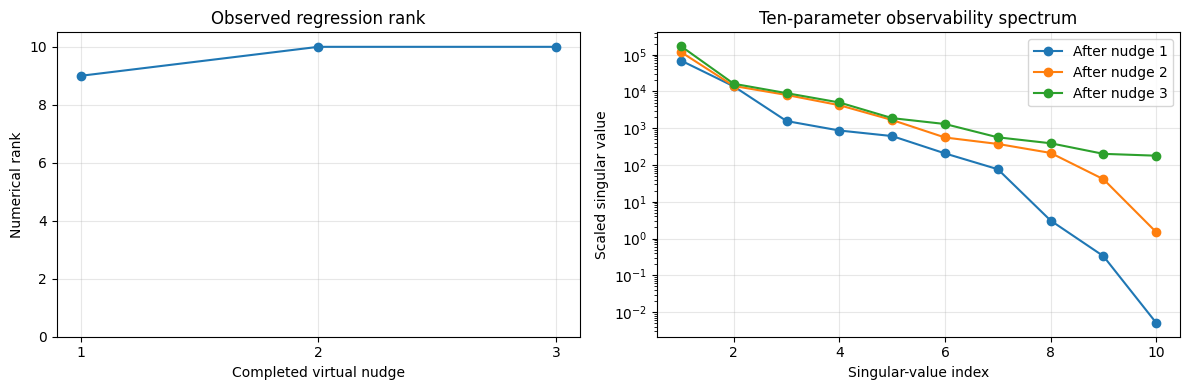

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1,2, figsize=(12,4))
ranks = [row['numerical_rank'] for row in result['records']]
axes[0].plot(range(1,4), ranks, 'o-')
axes[0].set(xlabel='Completed virtual nudge', ylabel='Numerical rank',
            xticks=[1,2,3], ylim=(0,10.5), title='Observed regression rank')
axes[0].grid(alpha=.3)

for row in result['records']:
    sv = np.asarray(row['singular_values'],float)
    axes[1].semilogy(np.arange(1,len(sv)+1), np.maximum(sv,1e-15), 'o-',
                     label=f"After nudge {row['nudge']}")
axes[1].set(xlabel='Singular-value index', ylabel='Scaled singular value',
            title='Ten-parameter observability spectrum')
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()

if ranks[-1] < 10:
    print('WARNING: Full numerical rank was NOT achieved. Increase excitation diversity,')
    print('consider longer observations, and inspect the nullspace before claiming full ID.')

## 6. Verify applied impulses and safety outcomes

Measured integrated impulse can differ slightly from the commanded body-frame impulse due to body rotation, even without measurement noise. A virtual force does not exert a reaction force on the servicer; the CBF applies to the separately simulated servicer motion.

In [6]:
display(pd.DataFrame([{
    'Nudge': r['nudge'],
    'Commanded J [N s]': r['impulse_commanded_Ns'],
    'Integrated |J| [N s]': r['impulse_measured_Ns'],
    'Force [N]': r['force_commanded_N'],
    'Pulse [s]': r['pulse_s'],
    'Observation [s]': r['observation_s'],
    'Drift [m]': r['drift_m'],
    'CoM speed [m/s]': r['speed_mps'],
    'CBF interventions (cumulative)': r['cbf_interventions'],
} for r in result['records']]))

assert all(r['impulse_measured_Ns'] <= settings.max_impulse_Ns+1e-6 for r in result['records'])
assert all(r['force_commanded_N'] <= settings.max_force_N+1e-6 for r in result['records'])
assert all(r['drift_m'] <= settings.max_target_displacement_m+1e-6 for r in result['records'])
print('Saved files:', sorted(p.name for p in OUTPUT.iterdir()))

,Nudge,Commanded J [N s],Integrated |J| [N s],Force [N],Pulse [s],Observation [s],Drift [m],CoM speed [m/s],CBF interventions (cumulative)
0,1,1.974399,1.974395,1.639866,1.204,20.0,0.081357,0.003984,0
1,2,1.080038,1.080037,2.465840,0.438,20.0,0.144701,0.003419,0
2,3,1.885975,1.885970,4.247691,0.444,8.0,0.151800,0.002800,0


Saved files: ['candidate_scores_1.npy', 'candidate_scores_2.npy', 'candidate_scores_3.npy', 'estimate_after_nudge_1.npz', 'estimate_after_nudge_2.npz', 'estimate_after_nudge_3.npz', 'records.json', 'summary.csv', 'validation_DEV_ONLY.json', 'virtual_trace.npz']


## 7. Inspect the asteroid trajectory

The trajectory includes a MuJoCo truth-based CoM trace **for development visualization only**. That truth is not passed into the estimator or optimization.

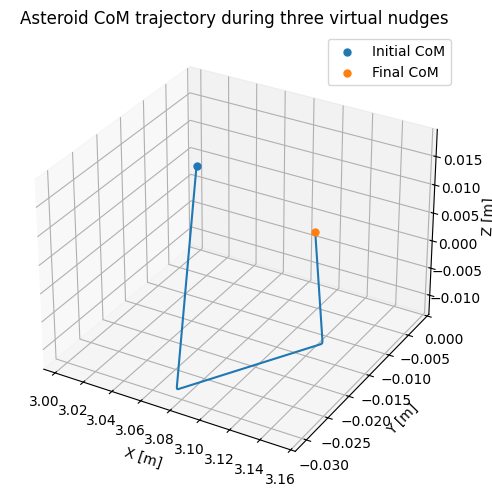

In [7]:
trace = np.load(OUTPUT/'virtual_trace.npz')['trace']
# Columns: time, stage (0=coast,1=virtual pulse), origin xyz, CoM xyz, CoM velocity xyz
fig = plt.figure(figsize=(9,5))
ax = fig.add_subplot(projection='3d')
ax.plot(trace[:,5], trace[:,6], trace[:,7], linewidth=1.5)
ax.scatter(*trace[0,5:8], s=25, label='Initial CoM')
ax.scatter(*trace[-1,5:8], s=25, label='Final CoM')
ax.set(xlabel='X [m]',ylabel='Y [m]',zlabel='Z [m]',
       title='Asteroid CoM trajectory during three virtual nudges')
ax.legend()
plt.tight_layout()
plt.show()

## 8. Optional: repeat with observation noise

Once the noise-free run succeeds and the estimated ten parameters are well-excited, change `noise_std` to `1e-4` and use a different output directory. Estimator covariance uses approximate design weights, not exact correlated sensor-noise propagation. Repeat multiple random seeds before making statistical claims.

In [8]:
# Uncomment to run an additional noisy experiment:
# noisy_settings = Virtual10Settings(noise_std=1e-4, rng_seed=20)
# noisy_result = run_virtual_three(ROOT, noisy_settings,
#     output_dir=ROOT/'results'/'three_nudge_virtual_10param_noisy')